# Human Activity Recognition: Tuning and Feature Selection

**AAI 501, University of San Diego** | Francois Lubin, Lernik Avetisyan, Alex Denbaugh

This notebook follows `01_baseline_models.ipynb` and addresses three of the proposal's focus issues:

- **(a) Generalization to new people.** Tune the three strongest baseline models with
  volunteer-wise cross-validation (`GroupKFold`), so no volunteer appears in both the
  training and validation folds, then check accuracy for each unseen test volunteer.
- **(c) Accuracy vs. number of features.** Rank the 561 features by random forest importance
  (Breiman, 2001) and find the smallest feature set that performs nearly as well as all 561.
- **(e) Training time and interpretability.** Record training time as features are removed
  and look at which sensor signals the top features come from.

The test set (9 volunteers) is used only for final evaluation. All choices (hyperparameters,
number of features) are made with cross-validation on the 21 training volunteers.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42
DATA_DIR = Path("data") / "UCI HAR Dataset"
assert DATA_DIR.exists(), f"Dataset not found at {DATA_DIR.resolve()}"

## 1. Load the data

Same loader as Notebook 1 (feature names made unique by appending their index).

In [2]:
def load_feature_names(data_dir):
    """Return 561 unique feature names, each suffixed with its index."""
    feats = pd.read_csv(data_dir / "features.txt", sep=r"\s+", header=None,
                        names=["idx", "name"])
    return [f"{name}__{idx}" for idx, name in zip(feats["idx"], feats["name"])]


def load_activity_labels(data_dir):
    """Return a dict mapping label id (1-6) to activity name."""
    acts = pd.read_csv(data_dir / "activity_labels.txt", sep=r"\s+", header=None,
                       names=["id", "activity"])
    return dict(zip(acts["id"], acts["activity"]))


def load_split(data_dir, split, feature_names):
    """Load features X, label ids y, and volunteer ids for 'train' or 'test'."""
    folder = data_dir / split
    X = pd.read_csv(folder / f"X_{split}.txt", sep=r"\s+", header=None,
                    names=feature_names)
    y = pd.read_csv(folder / f"y_{split}.txt", header=None).iloc[:, 0]
    subject = pd.read_csv(folder / f"subject_{split}.txt", header=None).iloc[:, 0]
    return X, y.rename("label"), subject.rename("subject")


feature_names = load_feature_names(DATA_DIR)
activity_map = load_activity_labels(DATA_DIR)
class_names = [activity_map[i] for i in sorted(activity_map)]

X_train, y_train, subj_train = load_split(DATA_DIR, "train", feature_names)
X_test, y_test, subj_test = load_split(DATA_DIR, "test", feature_names)

cv = GroupKFold(n_splits=5)
print("Train:", X_train.shape, f"({subj_train.nunique()} volunteers)")
print("Test: ", X_test.shape, f"({subj_test.nunique()} volunteers)")

Train: (7352, 561) (21 volunteers)
Test:  (2947, 561) (9 volunteers)


In [3]:
# Show that GroupKFold keeps each volunteer in exactly one validation fold
fold_rows = []
for i, (tr, va) in enumerate(cv.split(X_train, y_train, groups=subj_train), start=1):
    fold_rows.append({"Fold": i,
                      "Validation volunteers": sorted(subj_train.iloc[va].unique().tolist()),
                      "Validation windows": len(va),
                      "Overlap with training": len(set(subj_train.iloc[tr]) & set(subj_train.iloc[va]))})
pd.DataFrame(fold_rows).set_index("Fold")

,Validation volunteers,Validation windows,Overlap with training
Fold,,,
1,"[14, 15, 19, 25]",1420,0
2,"[6, 16, 21, 22]",1420,0
3,"[3, 11, 17, 26]",1417,0
4,"[1, 7, 23, 30]",1410,0
5,"[5, 8, 27, 28, 29]",1685,0


## 2. Hyperparameter tuning with volunteer-wise cross-validation

We tune the three strongest models from Notebook 1. Each grid is small on purpose: the goal
is to see whether tuning helps at all, not to squeeze out the last 0.1%.

| Model | Parameters searched |
|---|---|
| Logistic regression | `C` (inverse regularization strength) |
| SVM (RBF kernel) | `C`, `gamma` (kernel width) |
| Gradient boosting | `learning_rate`, `max_leaf_nodes` |

In [4]:
search_spaces = {
    "Logistic regression": (
        make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
        {"logisticregression__C": [0.01, 0.1, 1, 10]},
    ),
    "SVM (RBF kernel)": (
        make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=RANDOM_STATE)),
        {"svc__C": [1, 10, 100], "svc__gamma": [1e-4, 5e-4, "scale"]},
    ),
    "Gradient boosting": (
        HistGradientBoostingClassifier(random_state=RANDOM_STATE),
        {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31]},
    ),
}

# Untuned test accuracy from Notebook 1, for comparison
baseline_test_acc = {"Logistic regression": 0.9552, "SVM (RBF kernel)": 0.9522,
                     "Gradient boosting": 0.9315}

searches, tuning_rows = {}, []
for name, (estimator, grid) in search_spaces.items():
    start = time.perf_counter()
    search = GridSearchCV(estimator, grid, cv=cv, scoring="accuracy", n_jobs=-1)
    search.fit(X_train, y_train, groups=subj_train)
    minutes = (time.perf_counter() - start) / 60
    searches[name] = search
    y_pred = search.predict(X_test)
    tuning_rows.append({
        "Model": name,
        "Best parameters": {k.split("__")[-1]: v for k, v in search.best_params_.items()},
        "CV accuracy (mean)": search.best_score_,
        "CV accuracy (std)": search.cv_results_["std_test_score"][search.best_index_],
        "Test accuracy (tuned)": accuracy_score(y_test, y_pred),
        "Test accuracy (baseline)": baseline_test_acc[name],
        "Test macro F1 (tuned)": f1_score(y_test, y_pred, average="macro"),
        "Search time (min)": minutes,
    })
    print(f"{name:20s} best={search.best_params_}  CV={search.best_score_:.4f}  "
          f"test={tuning_rows[-1]['Test accuracy (tuned)']:.4f}  ({minutes:.1f} min)")

tuning_df = pd.DataFrame(tuning_rows).set_index("Model")
tuning_df.style.format({c: "{:.4f}" for c in tuning_df.columns
                        if "accuracy" in c or "F1" in c} | {"Search time (min)": "{:.1f}"})

Logistic regression  best={'logisticregression__C': 0.1}  CV=0.9348  test=0.9498  (0.2 min)


SVM (RBF kernel)     best={'svc__C': 100, 'svc__gamma': 0.0001}  CV=0.9332  test=0.9562  (0.7 min)


Gradient boosting    best={'learning_rate': 0.1, 'max_leaf_nodes': 15}  CV=0.9347  test=0.9430  (2.7 min)


,Best parameters,CV accuracy (mean),CV accuracy (std),Test accuracy (tuned),Test accuracy (baseline),Test macro F1 (tuned),Search time (min)
Model,,,,,,,
Logistic regression,{'C': 0.1},0.9348,0.0397,0.9498,0.9552,0.9500,0.2
SVM (RBF kernel),"{'C': 100, 'gamma': 0.0001}",0.9332,0.0415,0.9562,0.9522,0.9561,0.7
Gradient boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 15}",0.9347,0.0376,0.9430,0.9315,0.9427,2.7


The cross-validation standard deviation shows how much accuracy changes from one group of
volunteers to another. Below, the full grid for the SVM shows how sensitive it is to `C` and `gamma`.

In [5]:
svm_cv = pd.DataFrame(searches["SVM (RBF kernel)"].cv_results_)
svm_grid = svm_cv.pivot_table(index="param_svc__C", columns="param_svc__gamma",
                              values="mean_test_score")
svm_grid.index.name, svm_grid.columns.name = "C", "gamma"
svm_grid.style.format("{:.4f}").background_gradient(cmap="Blues", axis=None)

gamma,0.000100,0.000500,scale
C,,,
1,0.9103,0.9224,0.9231
10,0.9304,0.9325,0.9241
100,0.9332,0.9300,0.9214


### Accuracy for each unseen test volunteer

Averages can hide people the model works poorly for. This is the most direct check of
generalization to new people (focus issue a).

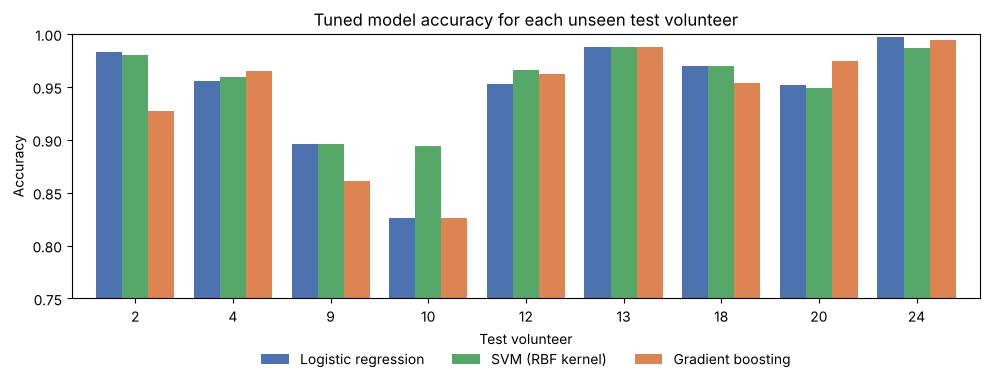

,Logistic regression,SVM (RBF kernel),Gradient boosting
Test volunteer,,,
2,0.983,0.980,0.927
4,0.956,0.959,0.965
9,0.896,0.896,0.861
10,0.827,0.895,0.827
12,0.953,0.966,0.963
13,0.988,0.988,0.988
18,0.970,0.970,0.953
20,0.952,0.949,0.975
24,0.997,0.987,0.995


In [6]:
per_person = pd.DataFrame({
    name: pd.Series(searches[name].predict(X_test) == y_test.values)
             .groupby(subj_test.values).mean()
    for name in searches
})
per_person.index.name = "Test volunteer"

ax = per_person.plot.bar(figsize=(10, 4), rot=0, width=0.8,
                         color=["#4C72B0", "#55A868", "#DD8452"])
ax.set_ylim(0.75, 1.0)
ax.set_ylabel("Accuracy")
ax.set_title("Tuned model accuracy for each unseen test volunteer")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

per_person.style.format("{:.3f}").highlight_min(axis=0, color="#f6c7b6")

## 3. Feature selection: how few features are enough?

**Method (no test-set leakage).**

1. Inside each cross-validation fold, fit a random forest on the fold's training volunteers
   and rank the 561 features by impurity-based importance.
2. Keep the top *k* features, train logistic regression (the best and fastest model), and
   score it on the fold's validation volunteers.
3. Average over the five folds for each *k*, and pick the **smallest *k* whose mean CV accuracy
   is within 1 percentage point of using all 561 features**.
4. Only then refit the ranking on all training data and report test accuracy for that *k*.

Ranking inside each fold matters: ranking on all training data first and then
cross-validating would let the validation volunteers influence which features are chosen.

We compare two versions of the ranking:

- **Plain RF ranking**: take the top *k* features as ranked.
- **Decorrelated RF ranking**: walk down the same ranking but skip any feature whose absolute
  correlation with an already-selected feature is above 0.8. The 0.8 threshold is fixed in
  advance, not tuned. Section 3.1 shows why this is needed.

### 3.1 Why plain importance ranking struggles here

Many of the 561 features are different statistics of the same signal (mean, min, max, energy
of the gravity component, for example). A random forest spreads importance across such
near-duplicates, so they all rank highly together.

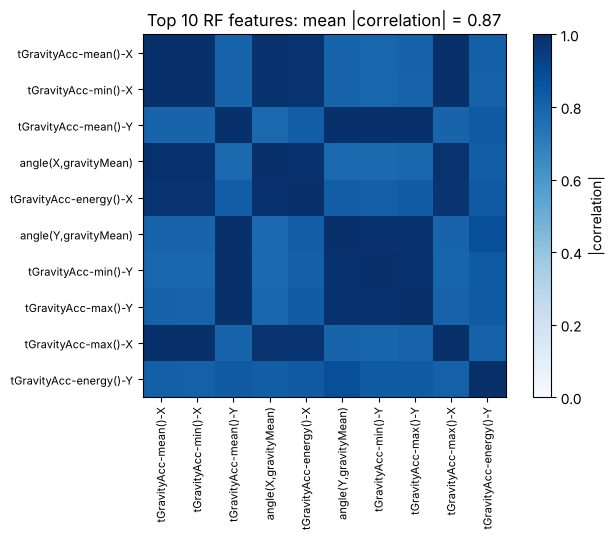

In [7]:
def rf_ranking(X, y):
    """Return feature importances sorted from most to least important."""
    rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE)
    rf.fit(X, y)
    return pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)


final_ranking = rf_ranking(X_train, y_train)
top10 = final_ranking.index[:10]
corr10 = X_train[top10].corr().abs()
mean_corr = corr10.values[np.triu_indices(10, 1)].mean()

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr10, cmap="Blues", vmin=0, vmax=1)
short = [n.rsplit("__", 1)[0] for n in top10]
ax.set_xticks(range(10), short, rotation=90, fontsize=8)
ax.set_yticks(range(10), short, fontsize=8)
fig.colorbar(im, ax=ax, label="|correlation|")
ax.set_title(f"Top 10 RF features: mean |correlation| = {mean_corr:.2f}")
plt.tight_layout()
plt.show()

Nearly all of the top 10 describe the phone's orientation relative to gravity. That separates
laying from the other activities, but it carries little information about walking vs. stairs
or sitting vs. standing, so the first 10 features add little beyond the first one or two.

### 3.2 Accuracy vs. number of features (cross-validation on training volunteers)

In [8]:
K_VALUES = [5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 561]
TOLERANCE = 0.01
CORR_THRESHOLD = 0.8


def decorrelate(ranked_names, X, threshold=CORR_THRESHOLD):
    """Walk down a ranking, skipping features too correlated with ones already kept."""
    corr = X.corr().abs()
    kept = []
    for name in ranked_names:
        if all(corr.at[name, k] < threshold for k in kept):
            kept.append(name)
    return kept


def make_lr():
    best_C = searches["Logistic regression"].best_params_["logisticregression__C"]
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=best_C, max_iter=3000,
                                            random_state=RANDOM_STATE))


def score_subset(cols, X_fit, y_fit, X_eval, y_eval):
    model = make_lr().fit(X_fit[cols], y_fit)
    return accuracy_score(y_eval, model.predict(X_eval[cols]))


cv_scores = {"Plain": {k: [] for k in K_VALUES}, "Decorrelated": {k: [] for k in K_VALUES}}
for fold, (tr, va) in enumerate(cv.split(X_train, y_train, groups=subj_train), start=1):
    X_tr, y_tr = X_train.iloc[tr], y_train.iloc[tr]
    X_va, y_va = X_train.iloc[va], y_train.iloc[va]
    ranking = rf_ranking(X_tr, y_tr)
    orders = {"Plain": list(ranking.index),
              "Decorrelated": decorrelate(ranking.index, X_tr)}
    for method, order in orders.items():
        for k in K_VALUES:
            if k == 561:
                cols = list(X_train.columns)
            elif k <= len(order):
                cols = order[:k]
            else:
                continue  # the decorrelated list is shorter than 561
            cv_scores[method][k].append(score_subset(cols, X_tr, y_tr, X_va, y_va))
    print(f"fold {fold}: {len(orders['Decorrelated'])} features survive decorrelation")

rows = []
for method, by_k in cv_scores.items():
    for k, scores in by_k.items():
        if len(scores) == cv.get_n_splits():
            rows.append({"Method": method, "k": k,
                         "CV mean": np.mean(scores), "CV std": np.std(scores)})
cv_curve = pd.DataFrame(rows)
full_cv = cv_curve.query("k == 561")["CV mean"].iloc[0]

k_star = {}
for method, grp in cv_curve.groupby("Method"):
    ok = grp[grp["CV mean"] >= full_cv - TOLERANCE]
    k_star[method] = int(ok["k"].min())
print(f"\nAll 561 features: CV accuracy {full_cv:.4f}")
for method, k in k_star.items():
    print(f"{method:13s} smallest k within {TOLERANCE:.0%}: k* = {k}")

cv_curve.pivot(index="k", columns="Method", values="CV mean").style.format("{:.4f}", na_rep="-")

fold 1: 172 features survive decorrelation


fold 2: 176 features survive decorrelation


fold 3: 183 features survive decorrelation


fold 4: 169 features survive decorrelation


fold 5: 174 features survive decorrelation

All 561 features: CV accuracy 0.9348
Decorrelated  smallest k within 1%: k* = 150
Plain         smallest k within 1%: k* = 300


Method,Decorrelated,Plain
k,,
5,0.8339,0.5533
10,0.8751,0.5977
20,0.8979,0.8675
30,0.9040,0.8945
50,0.9059,0.8963
75,0.9122,0.9051
100,0.9184,0.9158
150,0.9292,0.9225
200,-,0.9153


### 3.3 Test-set check

Now we fit both rankings on all 21 training volunteers and evaluate on the 9 unseen test
volunteers. We also run the tuned SVM on the decorrelated features and record logistic
regression training time (focus issue e).

In [9]:
orders_full = {"Plain": list(final_ranking.index),
               "Decorrelated": decorrelate(final_ranking.index, X_train)}
best_svm_params = {k.split("__")[-1]: v
                   for k, v in searches["SVM (RBF kernel)"].best_params_.items()}
print(f"{len(orders_full['Decorrelated'])} of 561 features survive decorrelation "
      f"(|r| < {CORR_THRESHOLD})")

test_rows = []
for k in K_VALUES:
    row = {"k": k}
    for method, order in orders_full.items():
        if k != 561 and k > len(order):
            continue
        cols = list(X_train.columns) if k == 561 else order[:k]
        start = time.perf_counter()
        row[f"LR test ({method})"] = score_subset(cols, X_train, y_train, X_test, y_test)
        row[f"LR train time, s ({method})"] = time.perf_counter() - start
        if method == "Decorrelated":
            svm = make_pipeline(StandardScaler(),
                                SVC(kernel="rbf", random_state=RANDOM_STATE,
                                    **best_svm_params)).fit(X_train[cols], y_train)
            row["SVM test (Decorrelated)"] = accuracy_score(y_test, svm.predict(X_test[cols]))
    test_rows.append(row)

test_curve = pd.DataFrame(test_rows).set_index("k")
test_curve = test_curve[["LR test (Plain)", "LR test (Decorrelated)",
                         "SVM test (Decorrelated)", "LR train time, s (Decorrelated)"]]
test_curve.index.name = "Features kept (k)"
test_curve.style.format("{:.4f}", na_rep="-").format(
    {"LR train time, s (Decorrelated)": "{:.2f}"}, na_rep="-")

177 of 561 features survive decorrelation (|r| < 0.8)


,LR test (Plain),LR test (Decorrelated),SVM test (Decorrelated),"LR train time, s (Decorrelated)"
Features kept (k),,,,
5,0.519511,0.817102,0.840855,0.03
10,0.532745,0.873770,0.889379,0.03
20,0.834069,0.888361,0.908042,0.05
30,0.860875,0.901256,0.913132,0.07
50,0.884289,0.929080,0.938921,0.10
75,0.890397,0.931456,0.935528,0.12
100,0.915507,0.932134,0.935188,0.14
150,0.932474,0.934510,0.935188,0.21
200,0.946725,-,-,-


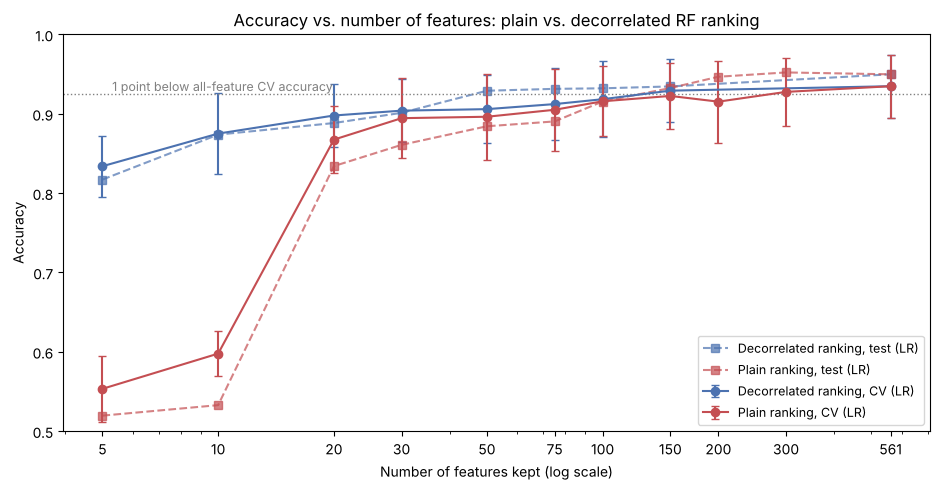

,k*,Share of 561,CV accuracy,LR test accuracy
Ranking,,,,
Decorrelated,150,27%,0.9292,0.9345
Plain,300,53%,0.9276,0.9522
All features,561,100%,0.9348,0.9498


In [10]:
colors = {"Plain": "#C44E52", "Decorrelated": "#4C72B0"}
fig, ax = plt.subplots(figsize=(9.5, 5))
for method, grp in cv_curve.groupby("Method"):
    ax.errorbar(grp["k"], grp["CV mean"], yerr=grp["CV std"], marker="o", capsize=3,
                color=colors[method], label=f"{method} ranking, CV (LR)")
    tc = test_curve[f"LR test ({method})"].dropna()
    ax.plot(tc.index, tc.values, marker="s", ls="--", color=colors[method], alpha=0.7,
            label=f"{method} ranking, test (LR)")
ax.axhline(full_cv - TOLERANCE, ls=":", color="gray", lw=1)
ax.text(5.3, full_cv - TOLERANCE + 0.004, "1 point below all-feature CV accuracy",
        color="gray", fontsize=9)
ax.set_xscale("log")
ax.set_xticks(K_VALUES)
ax.set_xticklabels(K_VALUES)
ax.set_xlabel("Number of features kept (log scale)")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.5, 1.0)
ax.set_title("Accuracy vs. number of features: plain vs. decorrelated RF ranking")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

summary = []
for method, k in k_star.items():
    summary.append({"Ranking": method, "k*": k, "Share of 561": k / 561,
                    "CV accuracy": cv_curve.query("Method == @method and k == @k")["CV mean"].iloc[0],
                    "LR test accuracy": test_curve.loc[k, f"LR test ({method})"]})
summary.append({"Ranking": "All features", "k*": 561, "Share of 561": 1.0, "CV accuracy": full_cv,
                "LR test accuracy": test_curve.loc[561, "LR test (Plain)"]})
pd.DataFrame(summary).set_index("Ranking").style.format(
    {"Share of 561": "{:.0%}", "CV accuracy": "{:.4f}", "LR test accuracy": "{:.4f}"})

### 3.4 Which sensors do the selected features come from?

Feature names follow a pattern (see `features_info.txt`): a prefix `t` (time domain) or `f`
(frequency domain), a signal such as `BodyAcc` (body acceleration), `GravityAcc` (gravity
component), or `BodyGyro` (rotation), and a statistic such as `mean()` or `std()`. The
`angle(...)` features measure the angle between two signal averages.

In [11]:
def describe_feature(name):
    """Split a HAR feature name into domain and sensor."""
    base = name.rsplit("__", 1)[0]
    if base.startswith("angle("):
        return "angle", "Gravity angle"
    domain = "time" if base[0] == "t" else "frequency"
    signal = base[1:].split("-")[0]
    sensor = ("Gravity (acc)" if "Gravity" in signal
              else "Body rotation (gyro)" if "Gyro" in signal
              else "Body motion (acc)")
    return domain, sensor


k_dec = k_star["Decorrelated"]
chosen = orders_full["Decorrelated"][:k_dec]
print(f"The {k_dec} decorrelated features chosen by cross-validation:")
for i, n in enumerate(chosen[:20], start=1):
    print(f"  {i:2d}. {n.rsplit('__', 1)[0]}")
if k_dec > 20:
    print(f"  ... and {k_dec - 20} more")

def share(names, col):
    return pd.DataFrame([describe_feature(n) for n in names],
                        columns=["Domain", "Sensor"])[col].value_counts(normalize=True)

pd.DataFrame({
    f"Chosen {k_dec} (decorrelated)": share(chosen, "Sensor"),
    "Top 10 (plain)": share(final_ranking.index[:10], "Sensor"),
    "All 561": share(final_ranking.index, "Sensor"),
}).fillna(0).style.format("{:.0%}")

The 150 decorrelated features chosen by cross-validation:
   1. tGravityAcc-mean()-X
   2. tGravityAcc-mean()-Y
   3. tGravityAccMag-std()
   4. angle(Z,gravityMean)
   5. tGravityAcc-arCoeff()-Z,2
   6. tGravityAcc-arCoeff()-Y,2
   7. tBodyAcc-correlation()-X,Y
   8. tGravityAcc-entropy()-Y
   9. tGravityAccMag-arCoeff()1
  10. fBodyGyro-maxInds-Z
  11. tGravityAcc-arCoeff()-X,1
  12. tGravityAcc-sma()
  13. fBodyGyro-meanFreq()-X
  14. fBodyGyro-bandsEnergy()-1,16
  15. tBodyAcc-correlation()-Y,Z
  16. tGravityAcc-std()-X
  17. tBodyGyro-entropy()-X
  18. fBodyAcc-meanFreq()-Z
  19. tGravityAcc-correlation()-X,Y
  20. fBodyGyro-maxInds-X
  ... and 130 more


,Chosen 150 (decorrelated),Top 10 (plain),All 561
Sensor,,,
Body motion (acc),40%,0%,52%
Body rotation (gyro),47%,0%,38%
Gravity (acc),11%,80%,9%
Gravity angle,2%,20%,1%


## 4. Takeaways

**Tuning (focus issue a)**

- Tuning changed little. Test accuracy after tuning: SVM 95.6% (baseline 95.2%), logistic
  regression 95.0% (baseline 95.5%), gradient boosting 94.3% (baseline 93.2%). Gradient
  boosting gained the most; logistic regression lost half a point.
- All three models score about 93.5% in volunteer-wise cross-validation, with a standard
  deviation of about 4 points between folds. Differences of under 1 point between models are
  therefore smaller than the variation between groups of people, and should not be read as
  one model being clearly better.
- **The volunteer matters more than the model.** Per-person test accuracy ranges from about
  83% (volunteer 10) to over 99% (volunteer 24). Volunteers 9 and 10 are hardest for every
  model. This is the clearest evidence about generalization to new people, and is worth
  investigating (for example, with their confusion matrices) in the report.

**Feature selection (focus issues c and e)**

- **Plain random forest importance is a poor feature selector here.** Its top 10 features are
  almost all versions of one gravity/orientation signal (mean |correlation| 0.87), so 10
  features give only about 53% test accuracy, and it needs 300 features (53%) to come within
  1 point of all 561 in cross-validation.
- **Removing redundant features fixes this.** Skipping any feature correlated above 0.8 with
  one already chosen gives 82% accuracy with 5 features, 87% with 10, and 93% with 50
  (logistic regression, unseen test volunteers). The tuned SVM does a little better on the same
  features: 84%, 89%, and 94%.
- By the 1-point cross-validation rule, the decorrelated ranking needs 150 features (27% of
  561) versus 300 for plain ranking. On the test set those 150 features reach 93.5%, compared
  with 95.0% using all 561.
- Fewer features also train faster: logistic regression trains about 3 times faster with 150
  features and about 5 to 6 times faster with 50 than with all 561.
- The decorrelated selection draws mostly on the body-motion accelerometer and gyroscope
  signals (87% of the 150 chosen), while the plain top 10 are entirely gravity/orientation
  features. This suggests both sensors are needed, which matters for devices that might drop
  the gyroscope to save battery.

**For the report:** a reasonable practical recommendation is about 50 decorrelated features
(9% of 561) for roughly 93-94% accuracy, or 150 for about 1 point less than the full set.
This answers the proposal's question of how few sensor features are enough.

**Next notebook:** PCA and clustering (k-means, hierarchical), testing whether clusters line
up with moving vs. still activities, and whether cluster distances help a classifier
(focus issue d).